# 03 – Graph Feature Engineering

## Objective

The objective of this notebook is to extend the traditional transaction-based 
XGBoost baseline with historical graph features for money laundering detection.

While the baseline model primarily considers individual transaction attributes, 
graph features provide additional information about account behaviour, 
transaction history, and relationships between accounts.

The aim is to investigate whether these structural and historical features 
can improve money laundering detection compared to the baseline model.

## Methodology

The following steps were performed:

1. **Data Preparation:** Loaded the IBM AML HI-Small dataset, converted 
   timestamps to datetime format, and sorted all transactions chronologically.

2. **Graph Representation:** Represented bank accounts as nodes and 
   transactions as directed edges from sender to receiver. Unique account 
   identifiers were created by combining bank and account identifiers. 
   Self-loops were retained.

3. **Exploratory Graph Analysis:** Examined the in-degree and out-degree 
   distributions using the first 10,000 transactions.

4. **Historical Feature Engineering:** Generated seven features describing 
   previous transaction activity, incoming and outgoing connections, and 
   repeated transactions between account pairs. The calculations were 
   implemented using Pandas operations without constructing an explicit 
   NetworkX graph.

5. **Temporal Data Leakage Prevention:** Calculated features using only 
   transactions with strictly earlier timestamps. Cumulative transaction 
   counts excluded the current timestamp, while historical degree values 
   were assigned using `merge_asof()` with `allow_exact_matches=False`. 
   This prevents current and future transactions from influencing 
   historical features.

6. **Feature Validation:** Checked missing values, negative values, 
   transaction count consistency, dataset size, and chronological ordering.

7. **Class Comparison:** Compared the mean graph feature values of normal 
   and laundering transactions using only the original training period, 
   ending on 6 September 2022 at 13:35.

## Generated Graph Features

All features describe account behaviour strictly before the current 
transaction timestamp.

| Feature | Definition | Potential Relevance |
|---|---|---|
| `sender_previous_tx_count` | Number of previous outgoing transactions by the sender | Identifies highly active sending accounts |
| `sender_previous_in_degree` | Number of distinct accounts that previously sent money to the sender | Captures fund collection behaviour |
| `sender_previous_out_degree` | Number of distinct accounts that previously received money from the sender | Captures fund distribution behaviour |
| `receiver_previous_tx_count` | Number of previous incoming transactions received by the receiver | Measures historical receiving activity |
| `receiver_previous_in_degree` | Number of distinct accounts that previously sent money to the receiver | Identifies potential fund aggregation |
| `receiver_previous_out_degree` | Number of distinct accounts that previously received money from the receiver | Captures the receiver's historical distribution behaviour |
| `previous_pair_tx_count` | Number of previous transactions from the same sender to the same receiver | Distinguishes new relationships from repeated transactions |

These features capture several potentially relevant transaction patterns:

- **Fan-in:** Multiple accounts transfer money to a single account.
- **Fan-out:** A single account distributes money to multiple accounts.
- **Repeated transactions:** Multiple transfers occur between the same 
  directed account pair.
- **High transaction activity:** Accounts exhibit unusually large numbers 
  of historical transactions or connections.

These patterns may provide useful signals for money laundering detection, 
but they can also occur in legitimate financial activities. Their predictive 
value must therefore be evaluated through model training.

## Key Findings

### Dataset and Graph Structure

| Metric | Result |
|---|---:|
| Total transactions | 5,078,345 |
| Original dataset columns | 11 |
| Unique sender accounts | 496,999 |
| Unique receiver accounts | 420,640 |
| Unique directed connections | 1,015,736 |
| Unique timestamps | 15,018 |
| Maximum transactions at one timestamp | 11,193 |
| Transactions with previous sender activity | 4,575,717 |
| Generated historical graph features | 7 |
| Enhanced dataset dimensions | 5,078,345 × 20 |

The dataset covers transactions from 1 September 2022 to 18 September 2022.

The number of unique directed connections represents approximately 20% 
of the total transaction count, indicating substantial repeated activity 
between account pairs.

The initial analysis of 10,000 transactions identified a maximum out-degree 
of 73 and a maximum in-degree of 3.

### Historical Feature Statistics

The following statistics were obtained across the complete transaction dataset.

| Feature | Mean | Median | Maximum |
|---|---:|---:|---:|
| Sender previous transaction count | 4,127.53 | 16 | 168,665 |
| Sender previous in-degree | 22.97 | 2 | 545 |
| Sender previous out-degree | 629.61 | 3 | 14,230 |
| Receiver previous transaction count | 12.94 | 11 | 1,083 |
| Receiver previous in-degree | 2.91 | 3 | 545 |
| Receiver previous out-degree | 6.05 | 1 | 14,230 |
| Previous pair transaction count | 7.44 | 5 | 88 |

Several features exhibit strongly right-skewed distributions, particularly 
the sender's historical transaction count and out-degree.

For example, 75% of transactions have a sender previous out-degree of 
six or less, while the maximum reaches 14,230. This indicates that a 
small number of highly connected accounts can substantially influence 
the overall mean.

One observed account reached a historical in-degree of 545 and an 
out-degree of 14,230. However, high connectivity alone does not establish 
money laundering activity.

### Normal vs. Laundering Transactions

The class comparison was restricted to the original training period 
to avoid using validation or test labels for feature exploration.

- **Training transactions:** 3,046,861
- **Normal transactions:** 3,044,564
- **Laundering transactions:** 2,297

| Feature | Normal (Mean) | Laundering (Mean) |
|---|---:|---:|
| Sender previous transaction count | 2,110.56 | 3,999.81 |
| Sender previous in-degree | 16.95 | 31.31 |
| Sender previous out-degree | 528.45 | 1,028.99 |
| Receiver previous transaction count | 6.95 | 7.35 |
| Receiver previous in-degree | 2.42 | 3.62 |
| Receiver previous out-degree | 4.90 | 1.94 |
| Previous pair transaction count | 3.53 | 0.77 |

The comparison reveals several notable differences:

- Laundering transactions have approximately 1.9 times higher mean 
  sender transaction counts.
- Sender in-degree and out-degree are substantially higher for 
  laundering transactions.
- Laundering transactions have higher mean receiver in-degree but 
  lower mean receiver out-degree.
- The mean previous pair transaction count is approximately 78% lower 
  for laundering transactions, suggesting less established transaction 
  relationships between the corresponding account pairs.
- Receiver transaction counts show a comparatively small difference 
  between the two classes.

These descriptive differences indicate that historical graph features 
may contain useful information for distinguishing laundering transactions 
from normal transactions.

However, the differences in mean values do not establish predictive 
performance, statistical significance, or causality. Highly active 
accounts may also influence these averages.

### Feature Validation

All implemented consistency checks passed successfully.

| Validation Check | Result |
|---|---|
| Missing values across all seven features | 0 |
| Negative values across all seven features | 0 |
| Sender out-degree exceeding previous outgoing transaction count | 0 |
| Receiver in-degree exceeding previous incoming transaction count | 0 |
| Pair count exceeding sender or receiver transaction count | 0 |
| Original transaction count preserved | Passed |
| Chronological ordering preserved | Passed |

These results confirm that the generated features satisfy the implemented 
basic consistency checks. They do not constitute an exhaustive verification 
of every historical feature value.

## Conclusion and Next Steps

This notebook successfully generated seven historical graph features for 
all 5,078,345 transactions while preserving the original transaction count 
and chronological ordering.

The training-only class comparison revealed differences in historical 
transaction activity, account connectivity, and repeated transaction 
relationships between normal and laundering transactions.

The results provide a motivation for incorporating graph features into 
the XGBoost model. However, no improvement in money laundering detection 
has yet been demonstrated.

The next steps are:

1. Complete the final feature verification and save the enhanced dataset 
   in an efficient format such as Parquet.
2. Create a new notebook, `04_graph_xgboost.ipynb`.
3. Combine the seven historical graph features with the existing 
   baseline transaction features.
4. Train a graph-enhanced XGBoost model using the same chronological 
   training, validation, and test partitions as the baseline.
5. Compare model performance using Average Precision, Precision, Recall, 
   F1-score, and cost-sensitive evaluation.
6. Evaluate the contribution of individual graph features through 
   feature importance and ablation analysis.

Model selection and threshold optimisation should be performed on the 
validation set, with the test set reserved for final evaluation.

At the current stage, the enhanced dataset exists in memory. Dataset 
export, graph-enhanced model training, and performance evaluation have 
not yet been performed.

The central research question remains whether historical graph features 
can improve money laundering detection compared to the traditional 
XGBoost baseline.

In [1]:
import pandas as pd
import networkx as nx

print("Graph analysis ready!")

Graph analysis ready!


In [2]:
df = pd.read_csv("../data/HI-Small_Trans.csv")

print(df.shape)
print(df.columns.tolist())

(5078345, 11)
['Timestamp', 'From Bank', 'Account', 'To Bank', 'Account.1', 'Amount Received', 'Receiving Currency', 'Amount Paid', 'Payment Currency', 'Payment Format', 'Is Laundering']


In [3]:
df["sender"] = (
    df["From Bank"].astype(str) + "_" +
    df["Account"].astype(str)
)

df["receiver"] = (
    df["To Bank"].astype(str) + "_" +
    df["Account.1"].astype(str)
)

df[["sender", "receiver"]].head()

,sender,receiver
0,10_8000EBD30,10_8000EBD30
1,3208_8000F4580,1_8000F5340
2,3209_8000F4670,3209_8000F4670
3,12_8000F5030,12_8000F5030
4,10_8000F5200,10_8000F5200


In [4]:
edges = df[["sender", "receiver"]].copy()

print("Total transactions:", len(edges))
print("Unique senders:", edges["sender"].nunique())
print("Unique receivers:", edges["receiver"].nunique())

edges.head()

Total transactions: 5078345
Unique senders: 496999
Unique receivers: 420640


,sender,receiver
0,10_8000EBD30,10_8000EBD30
1,3208_8000F4580,1_8000F5340
2,3209_8000F4670,3209_8000F4670
3,12_8000F5030,12_8000F5030
4,10_8000F5200,10_8000F5200


In [5]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

df = df.sort_values("Timestamp", kind="stable").reset_index(drop=True)

print(df[["Timestamp", "sender", "receiver"]].head())
print("Is sorted:", df["Timestamp"].is_monotonic_increasing)

   Timestamp          sender        receiver
0 2022-09-01  3209_8000F4670  3209_8000F4670
1 2022-09-01  1420_8005DFEB0  1420_8005DFEB0
2 2022-09-01    10_8000F6850    10_8000F6850
3 2022-09-01    12_8001167D0    12_8001167D0
4 2022-09-01     1_8001364A0     1_8001364A0
Is sorted: True


In [6]:
# İlk 10.000 işlem üzerinde test
sample = df.head(10000).copy()

# Her gönderen hesabın farklı alıcı sayısı
out_degree = sample.groupby("sender")["receiver"].nunique()

print(out_degree.head())

sender
10057_803AAB430    1
10057_803B01E40    1
10057_803B137E0    1
10057_803B46B20    1
10057_803B711E0    1
Name: receiver, dtype: int64


In [7]:
print(out_degree.value_counts().sort_index().head(20))

print("Maximum out-degree:", out_degree.max())
print("Average out-degree:", out_degree.mean())

receiver
1     9584
2       83
3        2
4        2
5        2
6        2
9        1
11       1
42       1
73       1
Name: count, dtype: int64
Maximum out-degree: 73
Average out-degree: 1.0250025829114577


In [8]:
in_degree = sample.groupby("receiver")["sender"].nunique()

print(in_degree.value_counts().sort_index().head(20))

print("Maximum in-degree:", in_degree.max())
print("Average in-degree:", in_degree.mean())

sender
1    9826
2      46
3       1
Name: count, dtype: int64
Maximum in-degree: 3
Average in-degree: 1.0048617441507142


In [9]:
print(df["Timestamp"].dtype)

print("Unique timestamps:", df["Timestamp"].nunique())

print("First timestamp:", df["Timestamp"].min())
print("Last timestamp:", df["Timestamp"].max())

print(df["Timestamp"].value_counts().head())

datetime64[us]
Unique timestamps: 15018
First timestamp: 2022-09-01 00:00:00
Last timestamp: 2022-09-18 16:18:00
Timestamp
2022-09-01 00:04:00    11193
2022-09-01 00:26:00    11025
2022-09-01 00:17:00    11018
2022-09-01 00:14:00    11003
2022-09-01 00:29:00    10998
Name: count, dtype: int64


In [10]:

counts = (
    df.groupby(["Timestamp", "sender"])
      .size()
      .rename("tx_count")
      .reset_index()
)


counts["sender_previous_tx_count"] = (
    counts.groupby("sender")["tx_count"].cumsum()
    - counts["tx_count"]
)


df = df.merge(
    counts[["Timestamp", "sender", "sender_previous_tx_count"]],
    on=["Timestamp", "sender"],
    how="left",
    validate="many_to_one"
)

print(df[[
    "Timestamp",
    "sender",
    "receiver",
    "sender_previous_tx_count"
]].head(10))

   Timestamp          sender        receiver  sender_previous_tx_count
0 2022-09-01  3209_8000F4670  3209_8000F4670                         0
1 2022-09-01  1420_8005DFEB0  1420_8005DFEB0                         0
2 2022-09-01    10_8000F6850    10_8000F6850                         0
3 2022-09-01    12_8001167D0    12_8001167D0                         0
4 2022-09-01     1_8001364A0     1_8001364A0                         0
5 2022-09-01     1_800139380     1_800139380                         0
6 2022-09-01   220_800132390   220_800132390                         0
7 2022-09-01     1_8001495E0     1_8001495E0                         0
8 2022-09-01  3292_8001541B0  3292_8001541B0                         0
9 2022-09-01  3211_8001583E0  3211_8001583E0                         0


In [11]:
# Check the distribution of previous transaction counts
print(df["sender_previous_tx_count"].describe())

# Count transactions with previous sender activity
print(
    "Transactions with previous activity:",
    (df["sender_previous_tx_count"] > 0).sum()
)

# Show examples with previous activity
df.loc[
    df["sender_previous_tx_count"] > 0,
    ["Timestamp", "sender", "receiver", "sender_previous_tx_count"]
].head(10)

count    5.078345e+06
mean     4.127531e+03
std      1.929811e+04
min      0.000000e+00
25%      4.000000e+00
50%      1.600000e+01
75%      4.100000e+01
max      1.686650e+05
Name: sender_previous_tx_count, dtype: float64
Transactions with previous activity: 4575717


,Timestamp,sender,receiver,sender_previous_tx_count
10986,2022-09-01 00:01:00,70_100428660,220_800132390,75
11031,2022-09-01 00:01:00,10_8003EDD40,10_8003EDD40,1
11039,2022-09-01 00:01:00,70_100428660,1292_800432260,75
11044,2022-09-01 00:01:00,70_100428660,1729_800487250,75
11076,2022-09-01 00:01:00,70_100428660,513_80062B450,75
11080,2022-09-01 00:01:00,70_100428660,701_80066B2D0,75
11102,2022-09-01 00:01:00,70_100428660,1124_8007051D0,75
11114,2022-09-01 00:01:00,1068_80078B850,1068_80078B850,1
11122,2022-09-01 00:01:00,12_8004B9AE0,1665_800827FD0,1
11126,2022-09-01 00:01:00,1601_80085B070,1601_80085B070,1


In [13]:
# Verify chronological order
assert df["Timestamp"].is_monotonic_increasing

# Find the first occurrence of each connection
first_connections = (
    df[["sender", "receiver", "Timestamp"]]
    .drop_duplicates(
        subset=["sender", "receiver"],
        keep="first"
    )
    .reset_index(drop=True)
)

print("Total transactions:", len(df))
print("Unique connections:", len(first_connections))

first_connections.head(10)

Total transactions: 5078345
Unique connections: 1015736


,sender,receiver,Timestamp
0,3209_8000F4670,3209_8000F4670,2022-09-01
1,1420_8005DFEB0,1420_8005DFEB0,2022-09-01
2,10_8000F6850,10_8000F6850,2022-09-01
3,12_8001167D0,12_8001167D0,2022-09-01
4,1_8001364A0,1_8001364A0,2022-09-01
5,1_800139380,1_800139380,2022-09-01
6,220_800132390,220_800132390,2022-09-01
7,1_8001495E0,1_8001495E0,2022-09-01
8,3292_8001541B0,3292_8001541B0,2022-09-01
9,3211_8001583E0,3211_8001583E0,2022-09-01


In [16]:
# Count new unique receivers per sender and timestamp
new_connections = (
    first_connections.groupby(["Timestamp", "sender"])
    .size()
    .rename("new_receivers")
    .reset_index()
)

# Calculate cumulative unique receivers
new_connections["cumulative_out_degree"] = (
    new_connections.groupby("sender")["new_receivers"].cumsum()
)

# Exclude connections created at the current timestamp
new_connections["sender_previous_out_degree"] = (
    new_connections["cumulative_out_degree"]
    - new_connections["new_receivers"]
)

new_connections.sort_values(
    "sender_previous_out_degree",
    ascending=False
).head(10)

,Timestamp,sender,new_receivers,cumulative_out_degree,sender_previous_out_degree
831099,2022-09-02 23:57:00,70_100428660,1,14230,14229
831030,2022-09-02 23:56:00,70_100428660,1,14229,14228
830857,2022-09-02 23:54:00,70_100428660,4,14228,14224
830781,2022-09-02 23:53:00,70_100428660,1,14224,14223
830721,2022-09-02 23:52:00,70_100428660,3,14223,14220
830636,2022-09-02 23:51:00,70_100428660,1,14220,14219
830543,2022-09-02 23:50:00,70_100428660,1,14219,14218
830358,2022-09-02 23:48:00,70_100428660,4,14218,14214
830256,2022-09-02 23:47:00,70_100428660,2,14214,14212
830151,2022-09-02 23:46:00,70_100428660,4,14212,14208


In [17]:
# Prepare historical out-degree lookup table
out_degree_history = new_connections[
    ["Timestamp", "sender", "cumulative_out_degree"]
].sort_values("Timestamp")

# Match each transaction with the latest strictly earlier degree
df = pd.merge_asof(
    df,
    out_degree_history,
    on="Timestamp",
    by="sender",
    direction="backward",
    allow_exact_matches=False
)

# Assign zero to accounts without previous connections
df["sender_previous_out_degree"] = (
    df["cumulative_out_degree"].fillna(0).astype("int32")
)

df = df.drop(columns=["cumulative_out_degree"])

df[[
    "Timestamp",
    "sender",
    "receiver",
    "sender_previous_out_degree"
]].sort_values(
    "sender_previous_out_degree",
    ascending=False
).head(10)

,Timestamp,sender,receiver,sender_previous_out_degree
2692202,2022-09-05 20:10:00,70_100428660,795_800BEC5C0,14230
3845510,2022-09-08 05:06:00,70_100428660,132499_81278C310,14230
3845509,2022-09-08 05:06:00,70_100428660,4242_811B5F100,14230
3319936,2022-09-07 02:53:00,70_100428660,221374_80A171EA0,14230
3319949,2022-09-07 02:53:00,70_100428660,3051_80D2C2FF0,14230
2692280,2022-09-05 20:10:00,70_100428660,35925_810587A90,14230
2692281,2022-09-05 20:10:00,70_100428660,38437_8105C9FA0,14230
2692265,2022-09-05 20:10:00,70_100428660,219969_80CD03510,14230
2692266,2022-09-05 20:10:00,70_100428660,16586_80CEFB6B0,14230
2692273,2022-09-05 20:10:00,70_100428660,2454_80E033AC0,14230


In [18]:
# Check the distribution of historical out-degree
print(df["sender_previous_out_degree"].describe())

# Check for missing values
print("Missing values:", df["sender_previous_out_degree"].isna().sum())

# Validate historical out-degree against transaction count
print(
    "Invalid rows:",
    (df["sender_previous_out_degree"] >
     df["sender_previous_tx_count"]).sum()
)

print("Total transactions:", len(df))

count    5.078345e+06
mean     6.296092e+02
std      2.605274e+03
min      0.000000e+00
25%      2.000000e+00
50%      3.000000e+00
75%      6.000000e+00
max      1.423000e+04
Name: sender_previous_out_degree, dtype: float64
Missing values: 0
Invalid rows: 0
Total transactions: 5078345


In [19]:
# Count new unique senders per receiver and timestamp
new_in_connections = (
    first_connections.groupby(["Timestamp", "receiver"])
    .size()
    .rename("new_senders")
    .reset_index()
)

# Calculate cumulative in-degree
new_in_connections["cumulative_in_degree"] = (
    new_in_connections.groupby("receiver")["new_senders"].cumsum()
)

# Exclude connections created at the current timestamp
new_in_connections["receiver_previous_in_degree"] = (
    new_in_connections["cumulative_in_degree"]
    - new_in_connections["new_senders"]
)

new_in_connections.sort_values(
    "receiver_previous_in_degree",
    ascending=False
).head(10)

,Timestamp,receiver,new_senders,cumulative_in_degree,receiver_previous_in_degree
851815,2022-09-02 23:58:00,70_100428660,1,545,544
851684,2022-09-02 23:56:00,70_100428660,1,544,543
851594,2022-09-02 23:55:00,70_100428660,1,543,542
851436,2022-09-02 23:53:00,70_100428660,2,542,540
850800,2022-09-02 23:46:00,70_100428660,1,540,539
850581,2022-09-02 23:44:00,70_100428660,1,539,538
850450,2022-09-02 23:43:00,70_100428660,1,538,537
850224,2022-09-02 23:41:00,70_100428660,1,537,536
849826,2022-09-02 23:38:00,70_100428660,1,536,535
849400,2022-09-02 23:35:00,70_100428660,1,535,534


In [20]:
# Prepare historical in-degree lookup table
in_degree_history = new_in_connections[
    ["Timestamp", "receiver", "cumulative_in_degree"]
].sort_values("Timestamp")

# Match transactions with strictly earlier in-degree values
df = pd.merge_asof(
    df,
    in_degree_history,
    on="Timestamp",
    by="receiver",
    direction="backward",
    allow_exact_matches=False
)

# Assign zero to accounts without previous connections
df["receiver_previous_in_degree"] = (
    df["cumulative_in_degree"].fillna(0).astype("int32")
)

df = df.drop(columns=["cumulative_in_degree"])

df[[
    "Timestamp",
    "sender",
    "receiver",
    "receiver_previous_in_degree"
]].sort_values(
    "receiver_previous_in_degree",
    ascending=False
).head(10)

,Timestamp,sender,receiver,receiver_previous_in_degree
4586273,2022-09-09 13:23:00,36098_8023F5FC0,70_100428660,545
4654643,2022-09-09 15:57:00,38672_80E75B310,70_100428660,545
4575368,2022-09-09 12:58:00,32613_8012CCAC0,70_100428660,545
4684927,2022-09-09 17:05:00,37467_80D06B000,70_100428660,545
4456701,2022-09-09 08:32:00,312340_806329940,70_100428660,545
4666097,2022-09-09 16:23:00,314410_806835780,70_100428660,545
4744422,2022-09-09 19:17:00,326887_80A230A80,70_100428660,545
4415521,2022-09-09 06:59:00,311839_806018480,70_100428660,545
4335245,2022-09-09 03:59:00,342567_81221FA90,70_100428660,545
4794728,2022-09-09 21:12:00,39077_803C8E640,70_100428660,545


In [21]:
# Count received transactions per account and timestamp
receiver_counts = (
    df.groupby(["Timestamp", "receiver"])
    .size()
    .rename("tx_count")
    .reset_index()
)

# Calculate previous received transaction counts
receiver_counts["receiver_previous_tx_count"] = (
    receiver_counts.groupby("receiver")["tx_count"].cumsum()
    - receiver_counts["tx_count"]
)

# Add the feature to the transaction dataset
df = df.merge(
    receiver_counts[
        ["Timestamp", "receiver", "receiver_previous_tx_count"]
    ],
    on=["Timestamp", "receiver"],
    how="left",
    validate="many_to_one"
)

df[[
    "Timestamp",
    "receiver",
    "receiver_previous_tx_count",
    "receiver_previous_in_degree"
]].sort_values(
    "receiver_previous_tx_count",
    ascending=False
).head(10)

,Timestamp,receiver,receiver_previous_tx_count,receiver_previous_in_degree
4867718,2022-09-09 23:57:00,70_100428660,1083,545
4866299,2022-09-09 23:54:00,70_100428660,1081,545
4866288,2022-09-09 23:54:00,70_100428660,1081,545
4865723,2022-09-09 23:53:00,70_100428660,1080,545
4865271,2022-09-09 23:52:00,70_100428660,1079,545
4864423,2022-09-09 23:50:00,70_100428660,1078,545
4863623,2022-09-09 23:48:00,70_100428660,1077,545
4862315,2022-09-09 23:45:00,70_100428660,1076,545
4861820,2022-09-09 23:44:00,70_100428660,1074,545
4861910,2022-09-09 23:44:00,70_100428660,1074,545


In [22]:
# Check feature statistics
print(df["receiver_previous_tx_count"].describe())

# Check missing values
print("Missing values:",
      df["receiver_previous_tx_count"].isna().sum())

# Validate in-degree against transaction count
print("Invalid rows:",
      (df["receiver_previous_in_degree"] >
       df["receiver_previous_tx_count"]).sum())

print("Total transactions:", len(df))

count    5.078345e+06
mean     1.293838e+01
std      1.482836e+01
min      0.000000e+00
25%      4.000000e+00
50%      1.100000e+01
75%      1.900000e+01
max      1.083000e+03
Name: receiver_previous_tx_count, dtype: float64
Missing values: 0
Invalid rows: 0
Total transactions: 5078345


In [23]:
# Reuse historical in-degree values for sender accounts
sender_in_history = in_degree_history.rename(
    columns={"receiver": "sender"}
)

# Match strictly earlier in-degree values
df = pd.merge_asof(
    df,
    sender_in_history,
    on="Timestamp",
    by="sender",
    direction="backward",
    allow_exact_matches=False
)

# Create sender historical in-degree feature
df["sender_previous_in_degree"] = (
    df["cumulative_in_degree"].fillna(0).astype("int32")
)

df = df.drop(columns=["cumulative_in_degree"])

df[[
    "Timestamp",
    "sender",
    "sender_previous_in_degree",
    "sender_previous_out_degree"
]].sort_values(
    "sender_previous_in_degree",
    ascending=False
).head(10)

,Timestamp,sender,sender_previous_in_degree,sender_previous_out_degree
4403126,2022-09-09 06:31:00,70_100428660,545,14230
2634358,2022-09-05 17:10:00,70_100428660,545,14230
2634371,2022-09-05 17:10:00,70_100428660,545,14230
2634375,2022-09-05 17:10:00,70_100428660,545,14230
2634381,2022-09-05 17:10:00,70_100428660,545,14230
2634394,2022-09-05 17:10:00,70_100428660,545,14230
2634335,2022-09-05 17:10:00,70_100428660,545,14230
2634343,2022-09-05 17:10:00,70_100428660,545,14230
2634348,2022-09-05 17:10:00,70_100428660,545,14230
2634351,2022-09-05 17:10:00,70_100428660,545,14230


In [24]:
# Reuse historical out-degree values for receiver accounts
receiver_out_history = out_degree_history.rename(
    columns={"sender": "receiver"}
)

# Match strictly earlier out-degree values
df = pd.merge_asof(
    df,
    receiver_out_history,
    on="Timestamp",
    by="receiver",
    direction="backward",
    allow_exact_matches=False
)

# Create receiver historical out-degree feature
df["receiver_previous_out_degree"] = (
    df["cumulative_out_degree"].fillna(0).astype("int32")
)

df = df.drop(columns=["cumulative_out_degree"])

df[[
    "Timestamp",
    "receiver",
    "receiver_previous_in_degree",
    "receiver_previous_out_degree"
]].sort_values(
    "receiver_previous_out_degree",
    ascending=False
).head(10)

,Timestamp,receiver,receiver_previous_in_degree,receiver_previous_out_degree
4820219,2022-09-09 22:10:00,70_100428660,545,14230
4567027,2022-09-09 12:39:00,70_100428660,545,14230
4429579,2022-09-09 07:31:00,70_100428660,545,14230
4426610,2022-09-09 07:24:00,70_100428660,545,14230
4581922,2022-09-09 13:13:00,70_100428660,545,14230
4273974,2022-09-09 01:41:00,70_100428660,545,14230
4783155,2022-09-09 20:45:00,70_100428660,545,14230
4784038,2022-09-09 20:47:00,70_100428660,545,14230
4783110,2022-09-09 20:45:00,70_100428660,545,14230
4582757,2022-09-09 13:15:00,70_100428660,545,14230


In [25]:
# Count transactions per account pair and timestamp
pair_counts = (
    df.groupby(["Timestamp", "sender", "receiver"])
    .size()
    .rename("tx_count")
    .reset_index()
)

# Calculate historical transaction counts for each pair
pair_counts["previous_pair_tx_count"] = (
    pair_counts.groupby(["sender", "receiver"])["tx_count"].cumsum()
    - pair_counts["tx_count"]
)

# Add the feature to the main dataset
df = df.merge(
    pair_counts[
        ["Timestamp", "sender", "receiver", "previous_pair_tx_count"]
    ],
    on=["Timestamp", "sender", "receiver"],
    how="left",
    validate="many_to_one"
)

df[[
    "Timestamp",
    "sender",
    "receiver",
    "previous_pair_tx_count"
]].sort_values(
    "previous_pair_tx_count",
    ascending=False
).head(10)

,Timestamp,sender,receiver,previous_pair_tx_count
5074152,2022-09-10 23:36:00,14_80006FCE0,14_80006FCE0,88
5074014,2022-09-10 23:35:00,14_80006FCE0,14_80006FCE0,87
4999624,2022-09-10 14:18:00,14_80006FCE0,14_80006FCE0,86
4999116,2022-09-10 14:14:00,14_80006FCE0,14_80006FCE0,85
4998257,2022-09-10 14:07:00,14_80006FCE0,14_80006FCE0,84
4866884,2022-09-09 23:55:00,14_80006FCE0,14_80006FCE0,83
4866441,2022-09-09 23:54:00,14_80006FCE0,14_80006FCE0,82
4863404,2022-09-09 23:47:00,14_80006FCE0,14_80006FCE0,81
4833239,2022-09-09 22:39:00,14_80006FCE0,14_80006FCE0,80
4831937,2022-09-09 22:36:00,14_80006FCE0,14_80006FCE0,79


In [26]:
# Define all historical graph features
graph_features = [
    "sender_previous_tx_count",
    "sender_previous_in_degree",
    "sender_previous_out_degree",
    "receiver_previous_tx_count",
    "receiver_previous_in_degree",
    "receiver_previous_out_degree",
    "previous_pair_tx_count"
]

# Check descriptive statistics
display(df[graph_features].describe().T)

# Check missing and negative values
print("Missing values:")
print(df[graph_features].isna().sum())

print("\nNegative values:")
print((df[graph_features] < 0).sum())

# Check pair count consistency
print("\nInvalid pair counts:",
      ((df["previous_pair_tx_count"] >
        df["sender_previous_tx_count"]) |
       (df["previous_pair_tx_count"] >
        df["receiver_previous_tx_count"])).sum())

print("\nTotal transactions:", len(df))
print("Chronological order:",
      df["Timestamp"].is_monotonic_increasing)

,count,mean,std,min,25%,50%,75%,max
sender_previous_tx_count,5078345.0,4127.530693,19298.107259,0.0,4.0,16.0,41.0,168665.0
sender_previous_in_degree,5078345.0,22.969739,93.589994,0.0,1.0,2.0,3.0,545.0
sender_previous_out_degree,5078345.0,629.609176,2605.274106,0.0,2.0,3.0,6.0,14230.0
receiver_previous_tx_count,5078345.0,12.938378,14.828362,0.0,4.0,11.0,19.0,1083.0
receiver_previous_in_degree,5078345.0,2.910289,7.656543,0.0,2.0,3.0,3.0,545.0
receiver_previous_out_degree,5078345.0,6.049667,217.764205,0.0,1.0,1.0,2.0,14230.0
previous_pair_tx_count,5078345.0,7.444157,7.816555,0.0,1.0,5.0,12.0,88.0


Missing values:
sender_previous_tx_count        0
sender_previous_in_degree       0
sender_previous_out_degree      0
receiver_previous_tx_count      0
receiver_previous_in_degree     0
receiver_previous_out_degree    0
previous_pair_tx_count          0
dtype: int64

Negative values:
sender_previous_tx_count        0
sender_previous_in_degree       0
sender_previous_out_degree      0
receiver_previous_tx_count      0
receiver_previous_in_degree     0
receiver_previous_out_degree    0
previous_pair_tx_count          0
dtype: int64

Invalid pair counts: 0

Total transactions: 5078345
Chronological order: True


In [27]:
# Select the original training period
train_graph = df.loc[
    df["Timestamp"] <= pd.Timestamp("2022-09-06 13:35:00")
]

# Compare graph features by transaction class
comparison = train_graph.groupby("Is Laundering")[graph_features].mean().T

comparison.columns = ["Normal", "Laundering"]

display(comparison.round(2))

print("Training transactions:", len(train_graph))
print("Laundering transactions:", train_graph["Is Laundering"].sum())

,Normal,Laundering
sender_previous_tx_count,2110.56,3999.81
sender_previous_in_degree,16.95,31.31
sender_previous_out_degree,528.45,1028.99
receiver_previous_tx_count,6.95,7.35
receiver_previous_in_degree,2.42,3.62
receiver_previous_out_degree,4.90,1.94
previous_pair_tx_count,3.53,0.77


Training transactions: 3046861
Laundering transactions: 2297


# Exploratory Graph Feature Analysis

In [30]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

FIGURE_DIR = Path("../figures/graph_features")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

NORMAL_COLOR = "#64748B"
LAUNDERING_COLOR = "#D97706"
POSITIVE_COLOR = "#0D9488"
NEGATIVE_COLOR = "#B45309"

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "pdf.fonttype": 42
})

feature_labels = {
    "sender_previous_tx_count": "Sender transaction count",
    "sender_previous_in_degree": "Sender in-degree",
    "sender_previous_out_degree": "Sender out-degree",
    "receiver_previous_tx_count": "Receiver transaction count",
    "receiver_previous_in_degree": "Receiver in-degree",
    "receiver_previous_out_degree": "Receiver out-degree",
    "previous_pair_tx_count": "Previous pair count"
}

def save_figure(fig, name):
    fig.savefig(
        FIGURE_DIR / f"{name}.png",
        dpi=300,
        bbox_inches="tight"
    )
    fig.savefig(
        FIGURE_DIR / f"{name}.pdf",
        bbox_inches="tight"
    )
    plt.show()

In [31]:
# Restrict exploratory analysis to the training period
train_graph = df.loc[
    df["Timestamp"] <= pd.Timestamp("2022-09-06 13:35:00")
]

comparison = (
    train_graph.groupby("Is Laundering")[graph_features]
    .mean()
    .T
)

comparison = comparison.rename(
    columns={0: "Normal", 1: "Laundering"}
)

display(comparison.round(2))

Is Laundering,Normal,Laundering
sender_previous_tx_count,2110.56,3999.81
sender_previous_in_degree,16.95,31.31
sender_previous_out_degree,528.45,1028.99
receiver_previous_tx_count,6.95,7.35
receiver_previous_in_degree,2.42,3.62
receiver_previous_out_degree,4.90,1.94
previous_pair_tx_count,3.53,0.77


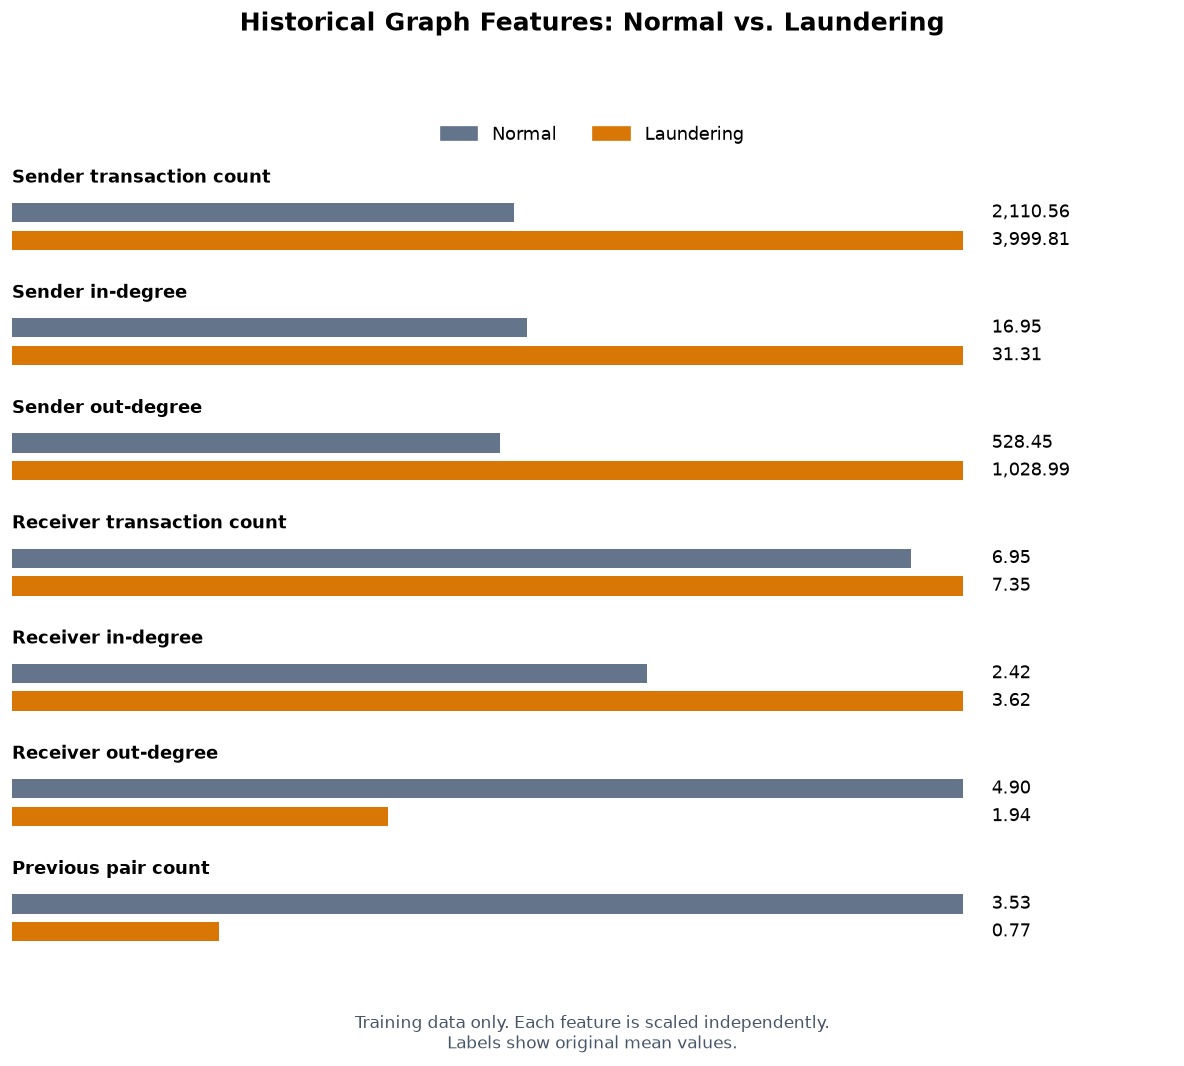

In [32]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(10, 9))

for i, (feature, row) in enumerate(comparison.iterrows()):

    normal = row["Normal"]
    laundering = row["Laundering"]
    max_value = max(normal, laundering, 1e-10)

    y = -i * 2.5

    # Display feature name
    ax.text(
        0, y + 0.65,
        feature_labels[feature],
        fontsize=11,
        fontweight="bold"
    )

    # Draw independently scaled bars
    ax.barh(
        y, normal / max_value,
        height=0.42,
        color=NORMAL_COLOR
    )

    ax.barh(
        y - 0.6, laundering / max_value,
        height=0.42,
        color=LAUNDERING_COLOR
    )

    # Display original mean values
    ax.text(1.03, y, f"{normal:,.2f}", va="center")
    ax.text(1.03, y - 0.6, f"{laundering:,.2f}", va="center")

ax.set_xlim(0, 1.22)
ax.set_ylim(-len(comparison) * 2.5 + 0.5, 1.5)
ax.axis("off")

ax.legend(
    handles=[
        Patch(color=NORMAL_COLOR, label="Normal"),
        Patch(color=LAUNDERING_COLOR, label="Laundering")
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 1.04),
    ncol=2
)

fig.suptitle(
    "Historical Graph Features: Normal vs. Laundering",
    fontsize=15,
    fontweight="bold"
)

fig.text(
    0.5, 0.02,
    "Training data only. Each feature is scaled independently.\n"
    "Labels show original mean values.",
    ha="center",
    fontsize=10,
    color="#475569"
)

fig.tight_layout(rect=[0, 0.05, 1, 0.94])

save_figure(fig, "01_graph_feature_mean_comparison")

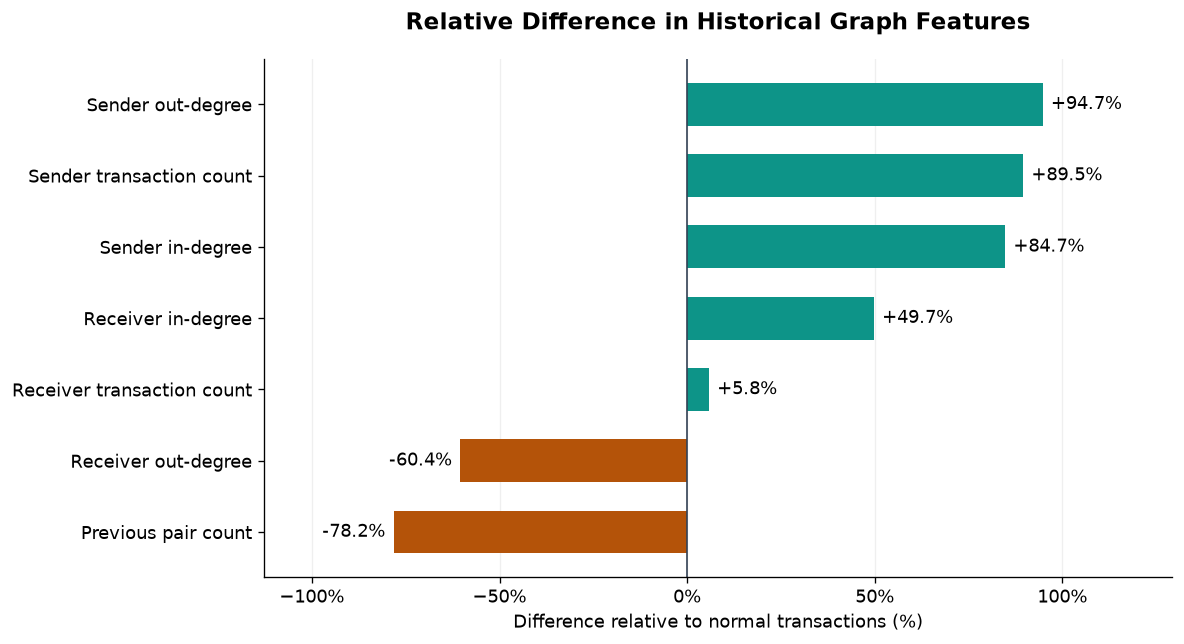

In [33]:
# Calculate relative differences between class means
relative_difference = (
    (comparison["Laundering"] - comparison["Normal"])
    / comparison["Normal"].replace(0, np.nan)
    * 100
).dropna().sort_values()

labels = relative_difference.index.map(feature_labels)

colors = [
    POSITIVE_COLOR if value >= 0 else NEGATIVE_COLOR
    for value in relative_difference
]

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.barh(
    labels,
    relative_difference,
    color=colors,
    height=0.6
)

ax.axvline(0, color="#334155", linewidth=1)

for bar, value in zip(bars, relative_difference):

    ax.annotate(
        f"{value:+.1f}%",
        xy=(value, bar.get_y() + bar.get_height() / 2),
        xytext=(5 if value >= 0 else -5, 0),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center"
    )

ax.set_title(
    "Relative Difference in Historical Graph Features",
    pad=18
)

ax.set_xlabel("Difference relative to normal transactions (%)")

ax.xaxis.set_major_formatter(
    mticker.PercentFormatter(xmax=100)
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.margins(x=0.2)

fig.tight_layout()

save_figure(fig, "02_relative_feature_difference")

C:\Users\gokce\AppData\Local\Temp\ipykernel_48412\4221107191.py:25: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(
C:\Users\gokce\AppData\Local\Temp\ipykernel_48412\4221107191.py:25: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(
C:\Users\gokce\AppData\Local\Temp\ipykernel_48412\4221107191.py:25: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(
C:\Users\gokce\AppData\Local\Temp\ipykernel_48412\4221107191.py:25: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(
C:\Users\gokce\AppData\L

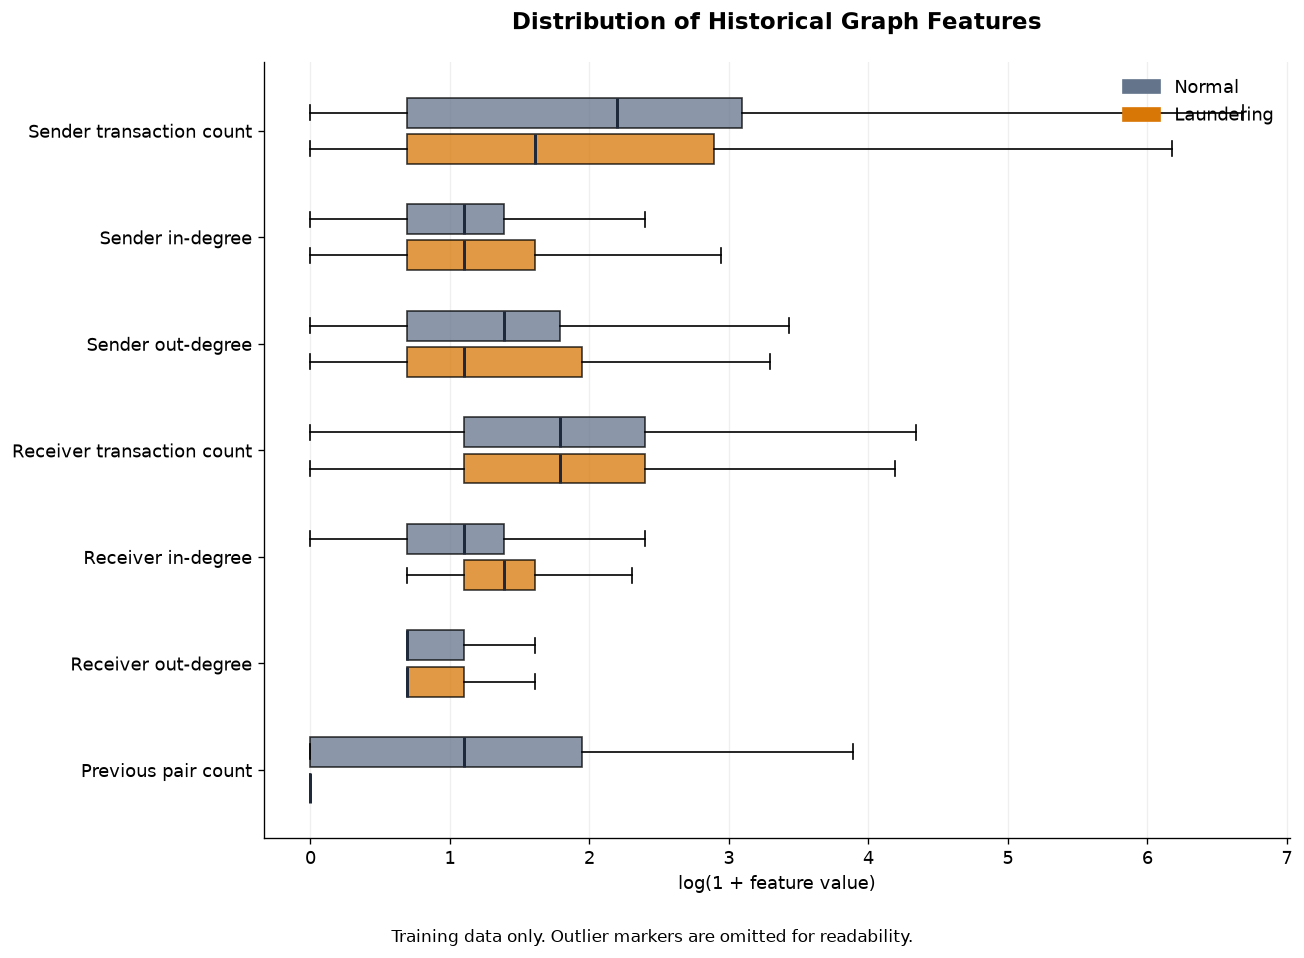

In [34]:
from matplotlib.patches import Patch

normal_data = train_graph.loc[
    train_graph["Is Laundering"] == 0,
    graph_features
]

laundering_data = train_graph.loc[
    train_graph["Is Laundering"] == 1,
    graph_features
]

fig, ax = plt.subplots(figsize=(11, 8))

for i, feature in enumerate(graph_features):

    # Apply log transformation to handle skewed distributions
    normal_values = np.log1p(normal_data[feature].to_numpy())
    laundering_values = np.log1p(
        laundering_data[feature].to_numpy()
    )

    y = len(graph_features) - i

    bp = ax.boxplot(
        [normal_values, laundering_values],
        positions=[y + 0.17, y - 0.17],
        vert=False,
        widths=0.28,
        patch_artist=True,
        showfliers=False,
        manage_ticks=False,
        medianprops={"color": "#1E293B", "linewidth": 1.8}
    )

    for patch, color in zip(
        bp["boxes"],
        [NORMAL_COLOR, LAUNDERING_COLOR]
    ):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)

ax.set_yticks(
    range(len(graph_features), 0, -1)
)

ax.set_yticklabels(
    [feature_labels[f] for f in graph_features]
)

ax.set_xlabel("log(1 + feature value)")

ax.set_title(
    "Distribution of Historical Graph Features",
    pad=20
)

ax.legend(
    handles=[
        Patch(color=NORMAL_COLOR, label="Normal"),
        Patch(color=LAUNDERING_COLOR, label="Laundering")
    ],
    loc="upper right"
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.5, 0.01,
    "Training data only. Outlier markers are omitted for readability.",
    ha="center",
    fontsize=10
)

fig.tight_layout(rect=[0, 0.04, 1, 1])

save_figure(fig, "03_graph_feature_distributions")

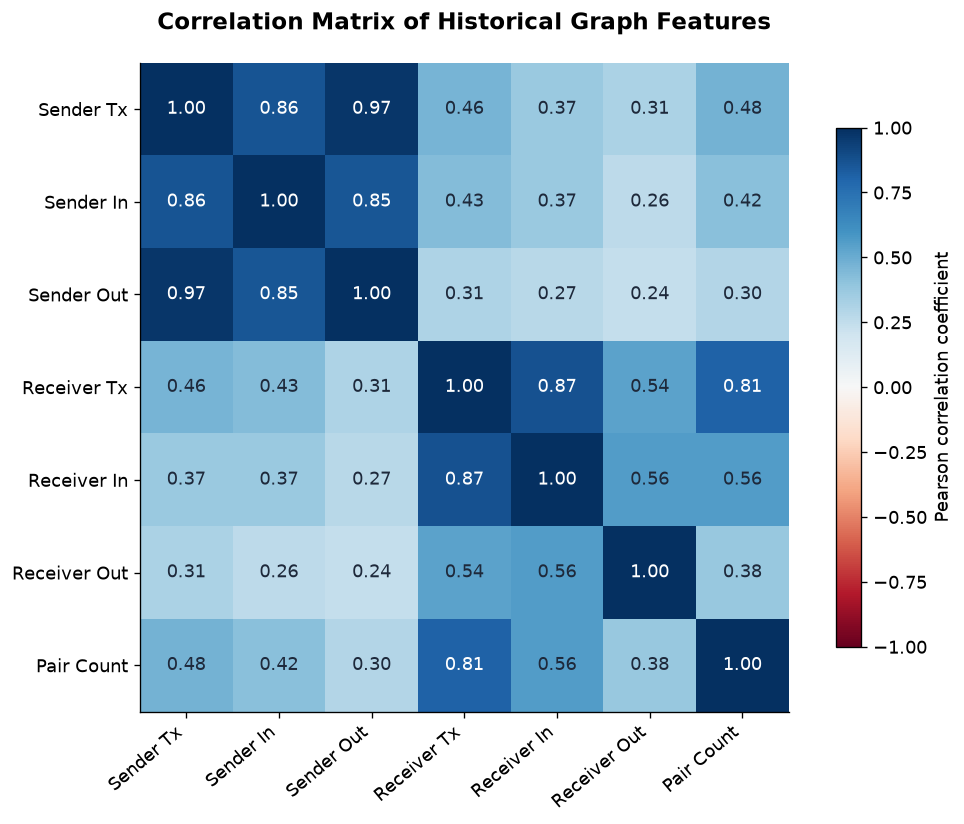

In [35]:
# Calculate Pearson correlations on log-transformed features
correlation = np.log1p(
    train_graph[graph_features]
).corr(method="pearson")

short_labels = [
    "Sender Tx",
    "Sender In",
    "Sender Out",
    "Receiver Tx",
    "Receiver In",
    "Receiver Out",
    "Pair Count"
]

fig, ax = plt.subplots(figsize=(9, 7))

heatmap = ax.imshow(
    correlation,
    cmap="RdBu",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(graph_features)))
ax.set_yticks(range(len(graph_features)))

ax.set_xticklabels(
    short_labels,
    rotation=40,
    ha="right"
)

ax.set_yticklabels(short_labels)

# Annotate correlation coefficients
for i in range(len(graph_features)):
    for j in range(len(graph_features)):

        value = correlation.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if abs(value) > 0.6 else "#1E293B"
        )

colorbar = fig.colorbar(
    heatmap,
    ax=ax,
    shrink=0.8
)

colorbar.set_label("Pearson correlation coefficient")

ax.set_title(
    "Correlation Matrix of Historical Graph Features",
    pad=20
)

fig.tight_layout()

save_figure(fig, "04_graph_feature_correlation")

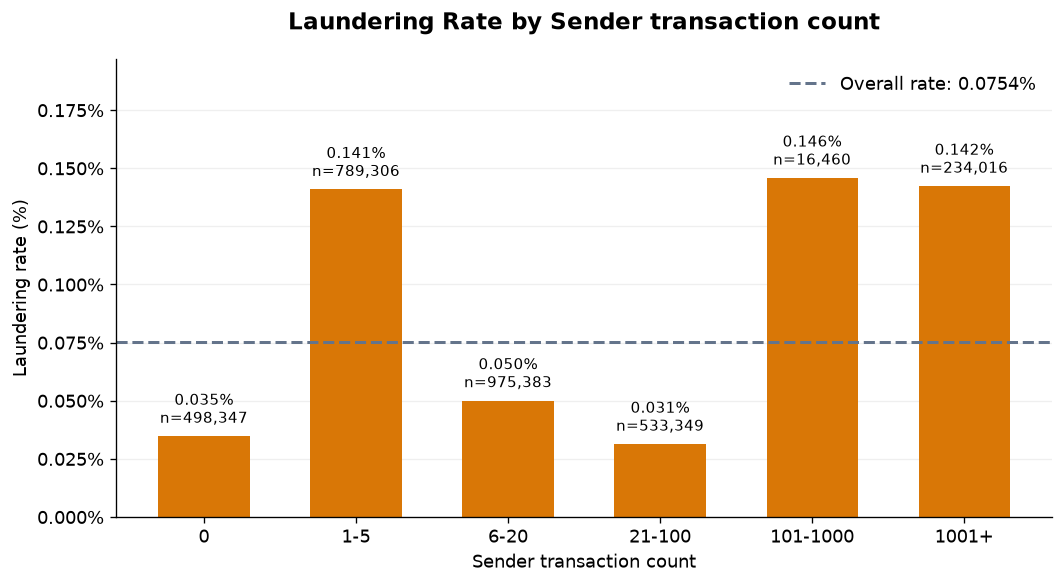

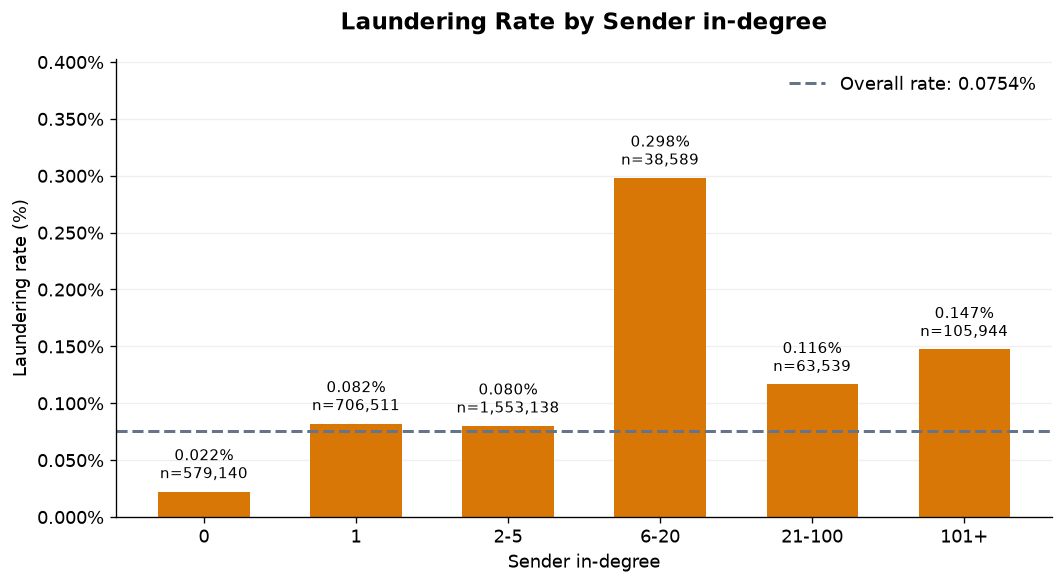

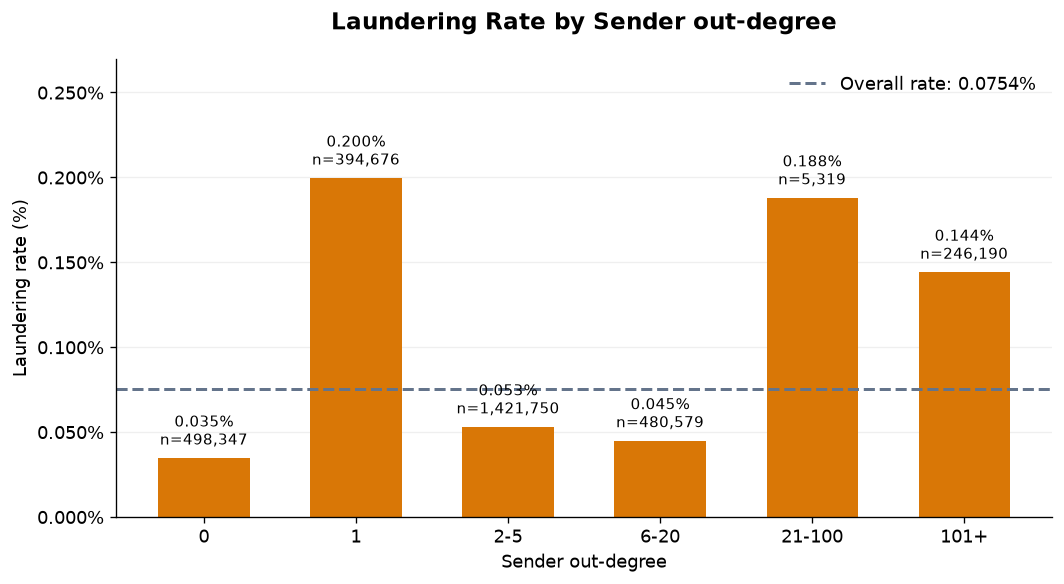

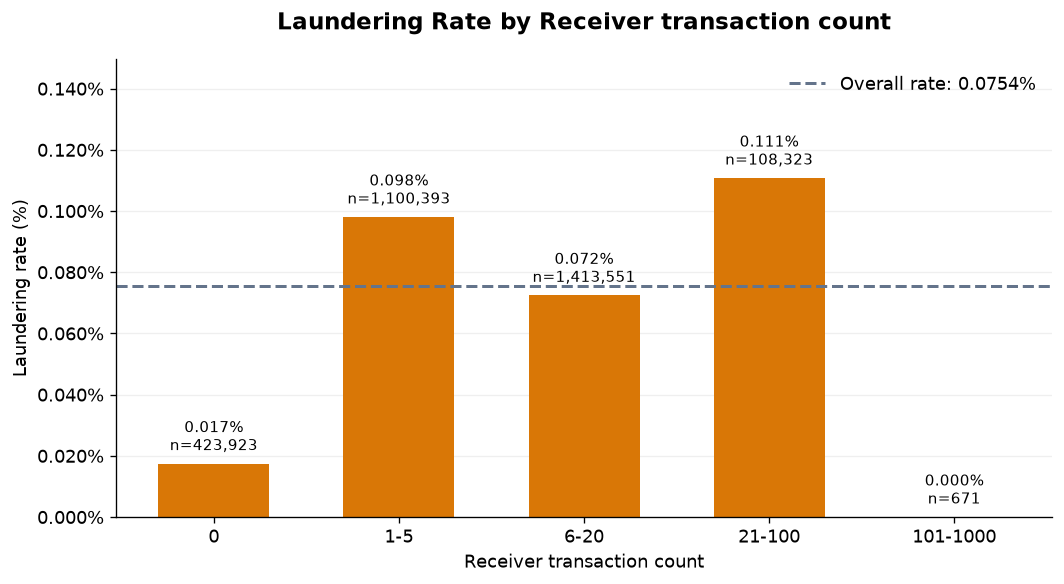

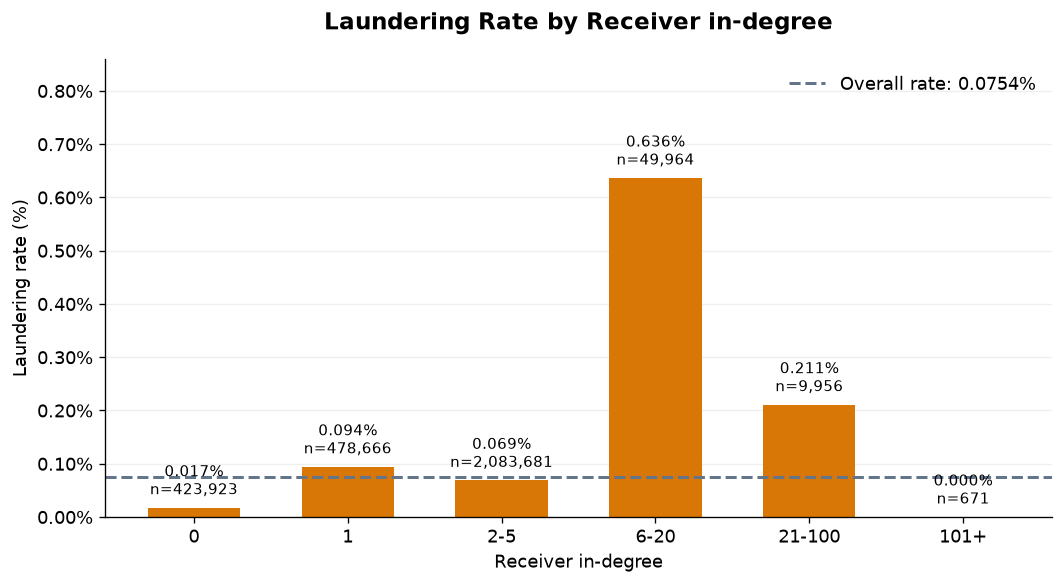

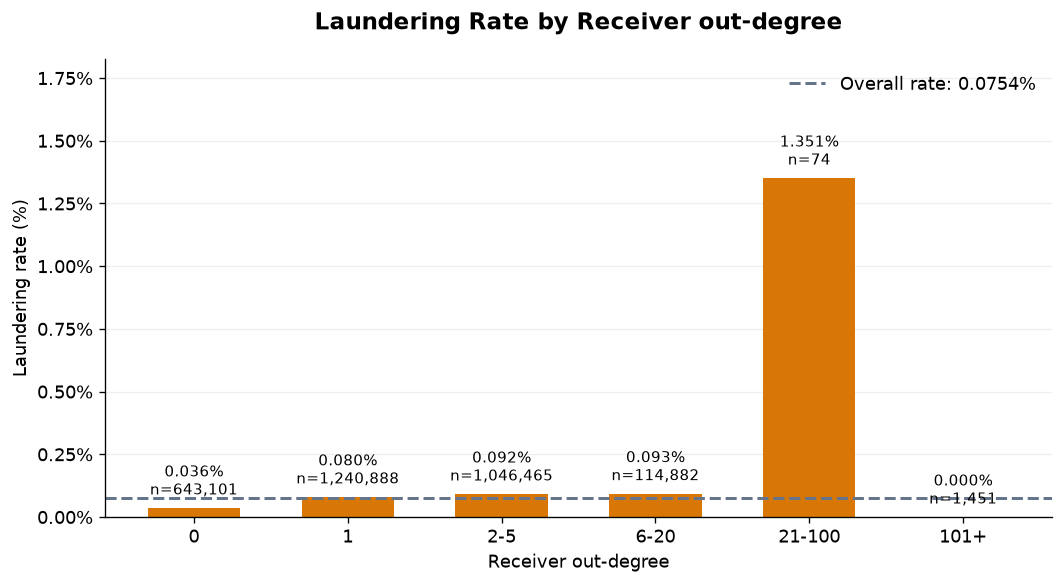

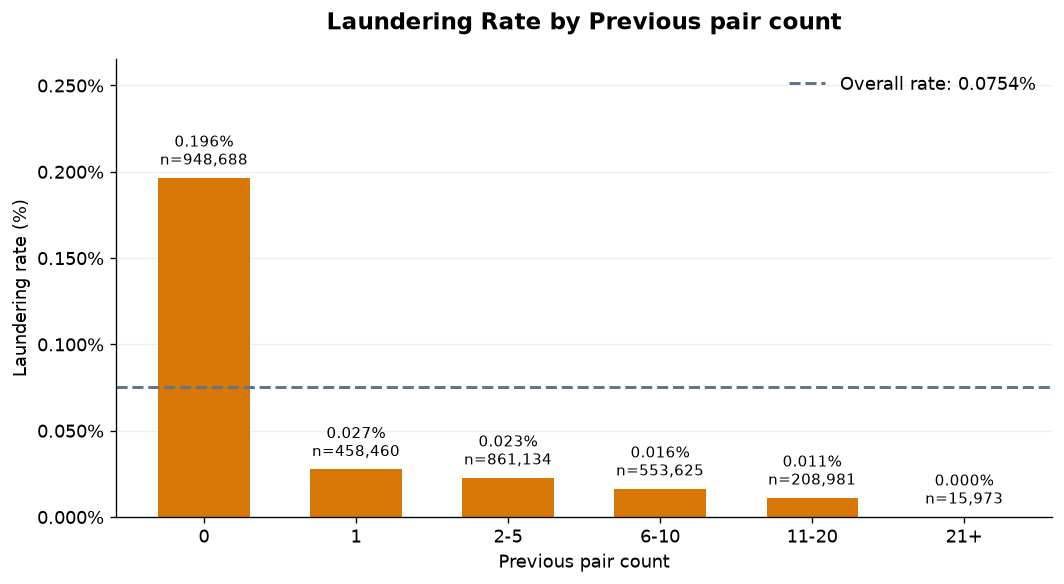

In [36]:
# Define feature-specific value intervals
degree_bins = [-1, 0, 1, 5, 20, 100, np.inf]
count_bins = [-1, 0, 5, 20, 100, 1000, np.inf]
pair_bins = [-1, 0, 1, 5, 10, 20, np.inf]

feature_bins = {
    "sender_previous_tx_count": count_bins,
    "sender_previous_in_degree": degree_bins,
    "sender_previous_out_degree": degree_bins,
    "receiver_previous_tx_count": count_bins,
    "receiver_previous_in_degree": degree_bins,
    "receiver_previous_out_degree": degree_bins,
    "previous_pair_tx_count": pair_bins
}

overall_rate = train_graph["Is Laundering"].mean() * 100

rate_tables = {}

for feature in graph_features:

    # Group transactions into feature-value intervals
    groups = pd.cut(
        train_graph[feature],
        bins=feature_bins[feature]
    )

    # Calculate transaction counts and laundering rates
    stats = (
        train_graph.groupby(groups, observed=True)["Is Laundering"]
        .agg(
            total_transactions="size",
            laundering_transactions="sum"
        )
    )

    stats["laundering_rate"] = (
        stats["laundering_transactions"]
        / stats["total_transactions"]
        * 100
    )

    rate_tables[feature] = stats

    labels = []

    for interval in stats.index:

        lower = int(interval.left) + 1

        if np.isinf(interval.right):
            label = f"{lower}+"
        else:
            upper = int(interval.right)
            label = str(lower) if lower == upper else f"{lower}-{upper}"

        labels.append(label)

    fig, ax = plt.subplots(figsize=(9, 5))

    bars = ax.bar(
        labels,
        stats["laundering_rate"],
        color=LAUNDERING_COLOR,
        width=0.6
    )

    # Add the overall training laundering rate
    ax.axhline(
        overall_rate,
        color=NORMAL_COLOR,
        linestyle="--",
        linewidth=1.8,
        label=f"Overall rate: {overall_rate:.4f}%"
    )

    # Annotate rates and group sizes
    for bar, rate, count in zip(
        bars,
        stats["laundering_rate"],
        stats["total_transactions"]
    ):

        ax.annotate(
            f"{rate:.3f}%\nn={count:,}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height()
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9
        )

    ax.set_title(
        f"Laundering Rate by {feature_labels[feature]}",
        pad=18
    )

    ax.set_xlabel(feature_labels[feature])
    ax.set_ylabel("Laundering rate (%)")

    ax.yaxis.set_major_formatter(
        mticker.PercentFormatter(xmax=100)
    )

    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.margins(y=0.35)
    ax.legend()

    fig.tight_layout()

    save_figure(fig, f"05_rate_{feature}")

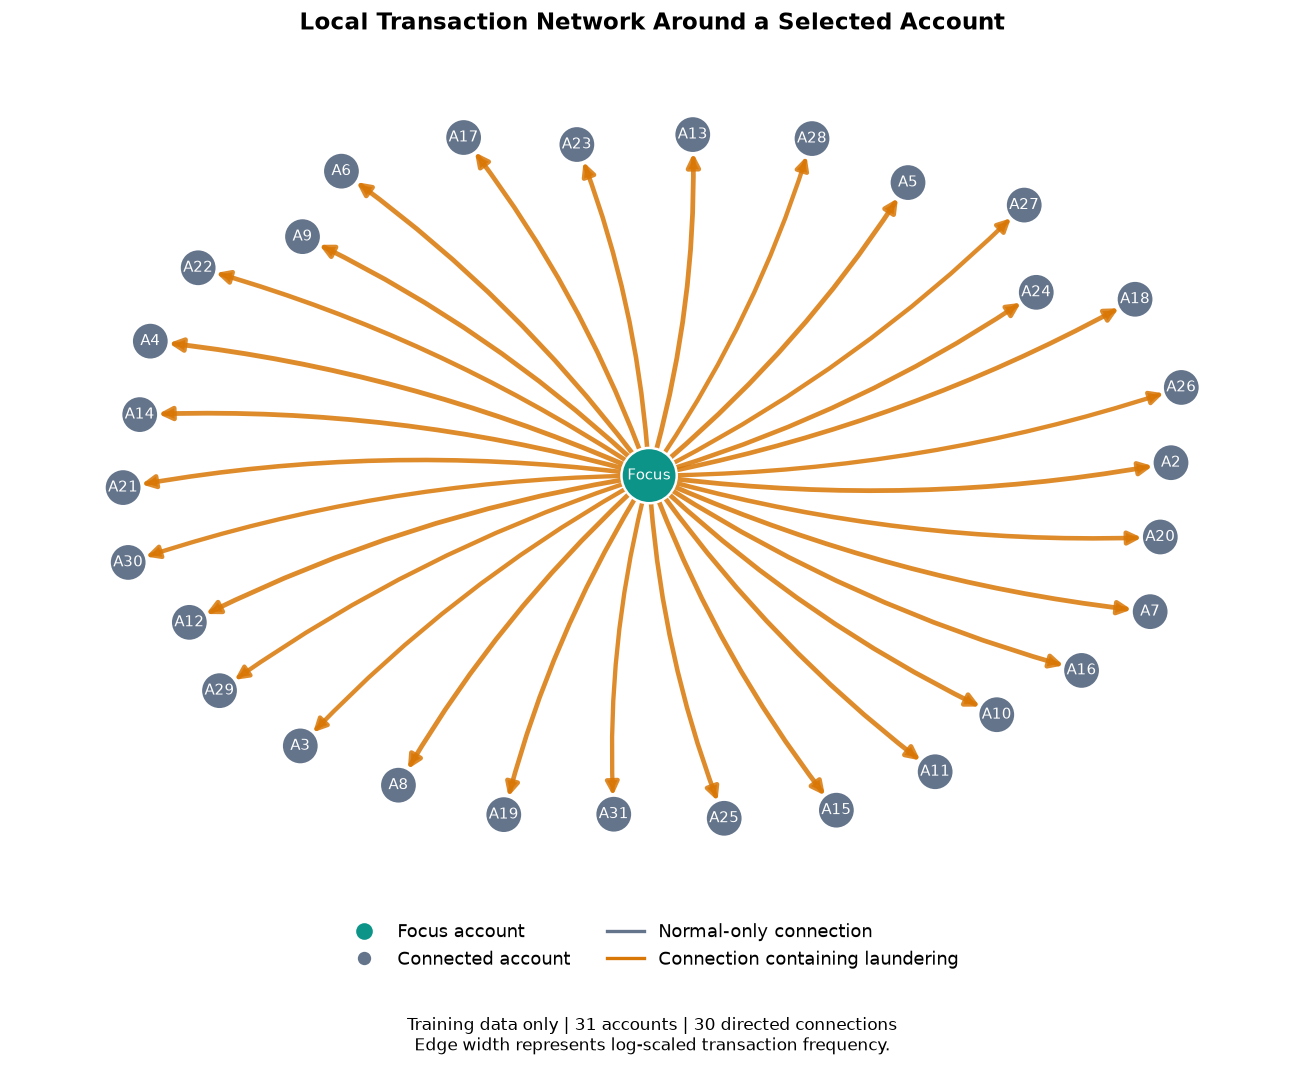

Focus account: 70_100428660
Total local transactions: 93951
Displayed accounts: 31
Displayed connections: 30


In [37]:
import networkx as nx
from matplotlib.lines import Line2D

# Select a sender with multiple laundering transactions
laundering_train = train_graph.loc[
    train_graph["Is Laundering"] == 1
]

focus_account = (
    laundering_train["sender"]
    .value_counts()
    .idxmax()
)

# Select transactions involving the focus account
local_transactions = train_graph.loc[
    (train_graph["sender"] == focus_account)
    | (train_graph["receiver"] == focus_account),
    ["sender", "receiver", "Is Laundering"]
]

# Aggregate repeated directed connections
local_edges = (
    local_transactions.groupby(["sender", "receiver"])
    .agg(
        transaction_count=("Is Laundering", "size"),
        laundering_count=("Is Laundering", "sum")
    )
    .reset_index()
)

# Limit the number of edges for visual clarity
local_edges = local_edges.sort_values(
    ["laundering_count", "transaction_count"],
    ascending=False
).head(30)

# Construct a directed graph
G = nx.from_pandas_edgelist(
    local_edges,
    source="sender",
    target="receiver",
    edge_attr=["transaction_count", "laundering_count"],
    create_using=nx.DiGraph()
)

# Generate a reproducible network layout
pos = nx.spring_layout(
    G,
    seed=42,
    k=1.4,
    iterations=100
)

fig, ax = plt.subplots(figsize=(11, 9))

node_colors = [
    POSITIVE_COLOR if node == focus_account else NORMAL_COLOR
    for node in G.nodes()
]

node_sizes = [
    1100 if node == focus_account else 500
    for node in G.nodes()
]

edge_colors = [
    LAUNDERING_COLOR
    if G[u][v]["laundering_count"] > 0
    else NORMAL_COLOR
    for u, v in G.edges()
]

edge_widths = [
    0.8 + np.log1p(G[u][v]["transaction_count"]) * 0.7
    for u, v in G.edges()
]

nx.draw_networkx_nodes(
    G, pos,
    node_color=node_colors,
    node_size=node_sizes,
    edgecolors="white",
    linewidths=1.5,
    ax=ax
)

nx.draw_networkx_edges(
    G, pos,
    edge_color=edge_colors,
    width=edge_widths,
    arrows=True,
    arrowsize=16,
    node_size=node_sizes,
    connectionstyle="arc3,rad=0.08",
    alpha=0.85,
    ax=ax
)

# Replace long account identifiers with readable labels
node_labels = {
    node: f"A{i + 1}"
    for i, node in enumerate(G.nodes())
}

node_labels[focus_account] = "Focus"

nx.draw_networkx_labels(
    G, pos,
    labels=node_labels,
    font_size=9,
    font_color="white",
    ax=ax
)

legend_elements = [
    Line2D(
        [0], [0], marker="o",
        color="none",
        markerfacecolor=POSITIVE_COLOR,
        markeredgecolor="none",
        markersize=10,
        label="Focus account"
    ),
    Line2D(
        [0], [0], marker="o",
        color="none",
        markerfacecolor=NORMAL_COLOR,
        markeredgecolor="none",
        markersize=8,
        label="Connected account"
    ),
    Line2D(
        [0], [0],
        color=NORMAL_COLOR,
        linewidth=2,
        label="Normal-only connection"
    ),
    Line2D(
        [0], [0],
        color=LAUNDERING_COLOR,
        linewidth=2,
        label="Connection containing laundering"
    )
]

ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=2
)

ax.set_title(
    "Local Transaction Network Around a Selected Account",
    pad=20
)

ax.axis("off")

fig.text(
    0.5, 0.02,
    f"Training data only | {G.number_of_nodes()} accounts | "
    f"{G.number_of_edges()} directed connections\n"
    "Edge width represents log-scaled transaction frequency.",
    ha="center",
    fontsize=10
)

fig.tight_layout(rect=[0, 0.07, 1, 1])

save_figure(fig, "06_local_transaction_network")

print("Focus account:", focus_account)
print("Total local transactions:", len(local_transactions))
print("Displayed accounts:", G.number_of_nodes())
print("Displayed connections:", G.number_of_edges())

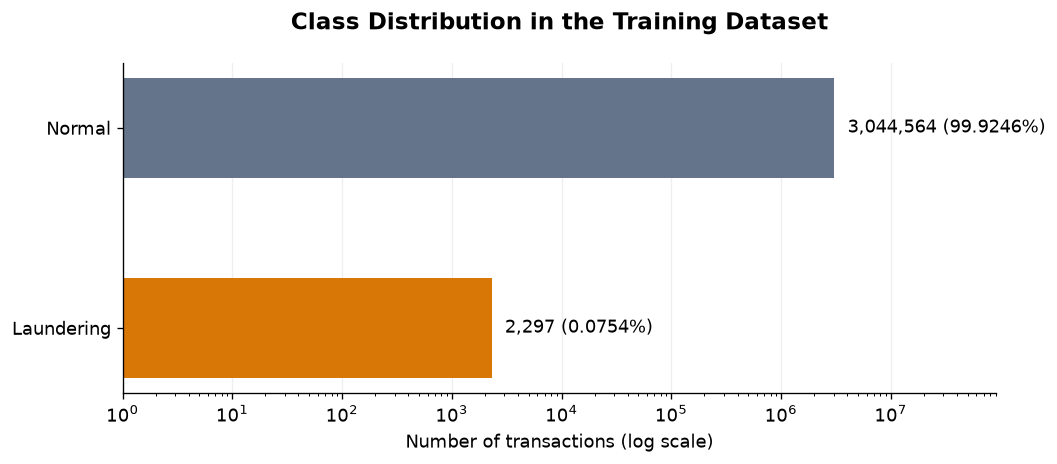

In [38]:
class_counts = (
    train_graph["Is Laundering"]
    .value_counts()
    .reindex([0, 1])
)

class_percentages = (
    class_counts / class_counts.sum() * 100
)

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.barh(
    ["Normal", "Laundering"],
    class_counts.values,
    color=[NORMAL_COLOR, LAUNDERING_COLOR],
    height=0.5
)

ax.set_xscale("log")
ax.invert_yaxis()

for bar, count, percentage in zip(
    bars,
    class_counts,
    class_percentages
):

    ax.annotate(
        f"{count:,} ({percentage:.4f}%)",
        xy=(count, bar.get_y() + bar.get_height() / 2),
        xytext=(8, 0),
        textcoords="offset points",
        va="center",
        fontsize=11
    )

ax.set_xlim(1, class_counts.max() * 30)

ax.set_title(
    "Class Distribution in the Training Dataset",
    pad=20
)

ax.set_xlabel("Number of transactions (log scale)")

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()

save_figure(fig, "07_training_class_distribution")